# 4. Etap 1 – preprocessing, imputacja i model bazowy

Cel: przewidzieć, czy spotkanie zakończy się **matchem** (obie osoby chcą się spotkać ponownie) na podstawie informacji znanych **przed spotkaniem** (ankieta wstępna obu osób i organizacja wydarzenia).

Notatnik korzysta z plików utworzonych w notatnikach 2 i 3:
`data/meetings_train.csv`, `data/meetings_test.csv` (podział grupowy po falach).
Zbiór testowy jest używany **tylko raz**, w ostatniej sekcji.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, BayesianRidge
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score,
                             f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
OUT = Path("out")
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

train = pd.read_csv("data/meetings_train.csv")
test = pd.read_csv("data/meetings_test.csv")

# cel binarny: match = obie osoby powiedziały "tak" (outcome == 1)
y_train = (train["outcome"] == 1).astype(int)
y_test = (test["outcome"] == 1).astype(int)
groups_train = train["wave_woman"]

print("train:", train.shape, "udział matchy:", round(y_train.mean(), 3))
print("test: ", test.shape, "udział matchy:", round(y_test.mean(), 3))

train: (3296, 173) udział matchy: 0.167
test:  (888, 173) udział matchy: 0.157


## 1. Wybór cech i typy danych

* **Identyfikatory i logistyka** (`iid`, `id`, `idg`, `partner`, `pid`, `wave`, `position`, `positin1`) – nie opisują ludzi, usuwamy. `wave` służy tylko do podziału grupowego.
* **Kolumny stałe** (`gender_*`) i **duplikaty** – np. `age_o_woman` to wiek mężczyzny, `samerace` i `int_corr` są identyczne w obu połówkach wiersza. Duplikaty wykrywamy automatycznie.
* **Tekst o dużej liczbie kategorii** (`field`, `career`, `from`, `undergra`, `zipcode`) – zastępujemy kodami `field_cd`, `career_c`; liczby z nich wyliczone (`mn_sat`, `tuition`, `income`) zostają.
* **Nominalne** (`race`, `goal`, `field_cd`, `career_c`, `condtn`) → one-hot.
* **Porządkowe** (`date`, `go_out` – częstość w skali 1–7, oceny 1–10 zainteresowań i ważności rasy/religii) – zostają jako liczby, bo kolejność ma znaczenie.
* **Znaczniki czasu** – w zbiorze ich nie ma (`wave` to numer wydarzenia, `date` to częstość randkowania). Nie tworzymy więc cech czasowych.
* **Nowe cechy**: różnica wieku i zgodność dziedziny studiów pary.

In [2]:
id_and_logistics = ["iid", "id", "idg", "partner", "pid", "wave", "position", "positin1"]
text_columns = ["field", "career", "from", "undergra", "zipcode"]
nominal_base = ["race", "goal", "field_cd", "career_c", "condtn"]


def base_name(column):
    return column.rsplit("_", 1)[0] if column.endswith(("_woman", "_man")) else column


def prepare_features(frame):
    """Wybór cech + cechy pochodne. Nie uczy się niczego z danych (bez przecieku)."""
    data = frame.drop(columns=["outcome"])
    data = data.drop(columns=[c for c in data.columns
                              if base_name(c) in id_and_logistics + text_columns + ["gender"]])
    data = data.copy()
    data["age_diff"] = data["age_man"] - data["age_woman"]
    data["same_field"] = (data["field_cd_woman"] == data["field_cd_man"]).astype(float)
    data.loc[data[["field_cd_woman", "field_cd_man"]].isna().any(axis=1), "same_field"] = np.nan
    return data


X_train_raw = prepare_features(train)
X_test_raw = prepare_features(test)

# duplikaty kolumn (np. age_o_woman == age_man) – wyznaczane na train, usuwane z obu zbiorów
duplicated = []
columns = list(X_train_raw.columns)
for i, left in enumerate(columns):
    for right in columns[i + 1:]:
        if right not in duplicated and X_train_raw[left].equals(X_train_raw[right]):
            duplicated.append(right)
X_train_raw = X_train_raw.drop(columns=duplicated)
X_test_raw = X_test_raw.drop(columns=duplicated)
print("usunięte duplikaty:", len(duplicated), duplicated[:8], "...")
print("liczba cech po selekcji:", X_train_raw.shape[1])

usunięte duplikaty: 19 ['condtn_man', 'int_corr_man', 'samerace_man', 'age_man', 'race_man', 'attr1_1_man', 'sinc1_1_man', 'intel1_1_man'] ...
liczba cech po selekcji: 127


## 2. Dane błędne

W notatnikach 1 i 3 wykryto: sumy punktów preferencji ≠ 100 (9 osób), oceny 0 w skali 1–10, wiek poza 18–55 i literówki w tekstach (poprawione w notatniku 2).
Dodatkowo blok `*4_1` (jak oceniają inni) w falach 6–9 zebrano w **skali 1–10 zamiast rozdziału 100 punktów** – mediana sumy ≈ 45 zamiast 100. Takie wartości nie są porównywalne z resztą, dlatego bloki punktowe (`*1_1`, `*2_1`, `*4_1`) przeliczamy na udziały sumujące się do 100 (operacja na pojedynczym wierszu – bez przecieku).

In [3]:
point_blocks = ["1_1", "2_1", "4_1"]
traits = ["attr", "sinc", "intel", "fun", "amb", "shar"]


def normalise_point_blocks(frame):
    frame = frame.copy()
    for person in ["woman", "man"]:
        for block in point_blocks:
            cols = [f"{t}{block}_{person}" for t in traits if f"{t}{block}_{person}" in frame]
            total = frame[cols].sum(axis=1, min_count=len(cols))
            frame[cols] = frame[cols].div(total.replace(0, np.nan), axis=0) * 100
    return frame


before = X_train_raw[[f"{t}4_1_woman" for t in traits]].sum(axis=1, min_count=6)
X_train_raw = normalise_point_blocks(X_train_raw)
X_test_raw = normalise_point_blocks(X_test_raw)
after = X_train_raw[[f"{t}4_1_woman" for t in traits]].sum(axis=1, min_count=6)
print("suma bloku 4_1 (kobiety) przed: mediana", before.median(), " min", before.min(), " max", before.max())
print("suma bloku 4_1 (kobiety) po:    mediana", round(after.median(), 1), " min", round(after.min(), 1), " max", round(after.max(), 1))

suma bloku 4_1 (kobiety) przed: mediana 100.0  min 35.0  max 110.0
suma bloku 4_1 (kobiety) po:    mediana 100.0  min 100.0  max 100.0


## 3. Braki danych

Kolumny z ponad 60% braków (na train) usuwamy – imputacja zgadywałaby większość wartości. Pozostałe braki uzupełniamy w potoku, dopasowanym tylko na części treningowej.

In [4]:
missing_share = X_train_raw.isna().mean().sort_values(ascending=False)
too_sparse = missing_share[missing_share > 0.6].index.tolist()
X_train_raw = X_train_raw.drop(columns=too_sparse)
X_test_raw = X_test_raw.drop(columns=too_sparse)
print("usunięte (>60% braków):", too_sparse)
print("udział pustych komórek (train):", round(X_train_raw.isna().mean().mean(), 3))
print("wiersze z jakimkolwiek brakiem:", int(X_train_raw.isna().any(axis=1).sum()), "z", len(X_train_raw))

nominal_columns = [c for c in X_train_raw.columns if base_name(c) in nominal_base]
skewed_columns = [c for c in X_train_raw.columns if base_name(c) in ["income", "tuition", "mn_sat"]]
numeric_columns = [c for c in X_train_raw.columns if c not in nominal_columns + skewed_columns]
print("cechy liczbowe/porządkowe:", len(numeric_columns), " skośne (log1p):", len(skewed_columns),
      " nominalne (one-hot):", len(nominal_columns))
missing_share.head(12).round(3)

usunięte (>60% braków): ['expnum_woman', 'expnum_man', 'mn_sat_man', 'income_man']
udział pustych komórek (train): 0.062
wiersze z jakimkolwiek brakiem: 2612 z 3296
cechy liczbowe/porządkowe: 111  skośne (log1p): 4  nominalne (one-hot): 8


expnum_woman     0.853
expnum_man       0.844
mn_sat_man       0.623
income_man       0.605
tuition_man      0.569
mn_sat_woman     0.459
income_woman     0.416
tuition_woman    0.383
sinc5_1_man      0.283
intel5_1_man     0.283
attr5_1_man      0.283
amb5_1_man       0.283
dtype: float64

## 4. Imputacja – 3 metody proste i 2 zaawansowane

* proste: **średnia**, **mediana**, **dominanta** (`SimpleImputer`),
* zaawansowane: **KNN** (k = 5, na cechach wystandaryzowanych) i **MICE** (`IterativeImputer` z regresją bayesowską, 10 iteracji, na cechach wystandaryzowanych, wartości ograniczone do ±5 odchyleń standardowych).

Każdy imputer dopasowujemy wyłącznie na train. Sprawdzamy, jak zmieniają się rozkłady trzech kolumn z dużą liczbą braków (porównanie z wartościami obserwowanymi, test Kołmogorowa–Smirnowa).

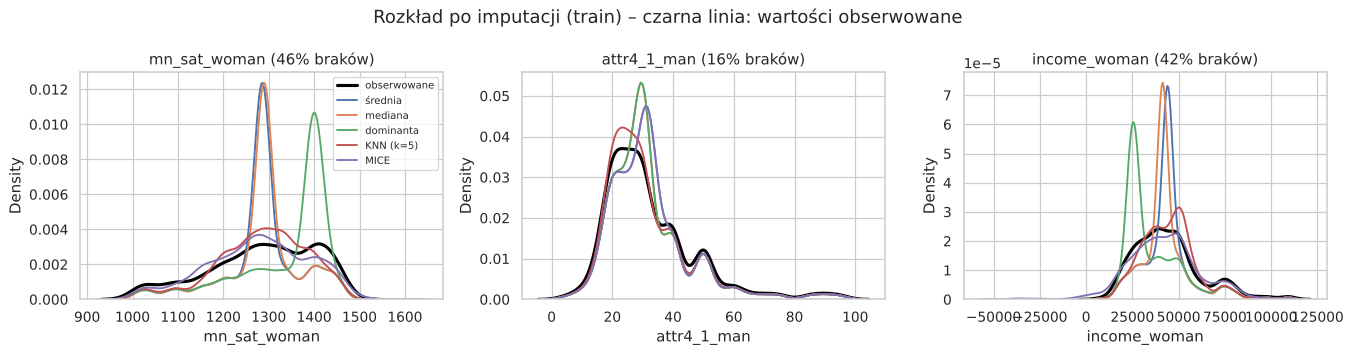

         kolumna     metoda  braki_%  średnia_po  odch_std_przed  odch_std_po  KS_uzupełnione_vs_obserwowane
0   mn_sat_woman    średnia     45.9     1285.67          118.44        87.10                          0.566
1   mn_sat_woman    mediana     45.9     1287.66          118.44        87.13                          0.480
2   mn_sat_woman  dominanta     45.9     1338.15          118.44       104.09                          0.734
3   mn_sat_woman  KNN (k=5)     45.9     1285.33          118.44        99.35                          0.247
4   mn_sat_woman       MICE     45.9     1277.03          118.44       111.64                          0.192
5    attr4_1_man    średnia     16.2       32.33           15.18        13.89                          0.647
6    attr4_1_man    mediana     16.2       31.96           15.18        13.92                          0.465
7    attr4_1_man  dominanta     16.2       31.96           15.18        13.92                          0.465
8    attr4_1_man  K

In [5]:
def make_imputer(name):
    if name == "średnia":
        return SimpleImputer(strategy="mean")
    if name == "mediana":
        return SimpleImputer(strategy="median")
    if name == "dominanta":
        return SimpleImputer(strategy="most_frequent")
    if name == "KNN (k=5)":
        # KNN liczy odległości, więc najpierw standaryzujemy cechy
        return Pipeline([("scale", StandardScaler()), ("impute", KNNImputer(n_neighbors=5))])
    if name == "MICE":
        # regresje łańcuchowe na cechach wystandaryzowanych; wartości ograniczone do +-5 odchyleń,
        # żeby przy silnie skorelowanych cechach regresja nie "uciekała" do absurdalnych liczb
        return Pipeline([("scale", StandardScaler()),
                         ("impute", IterativeImputer(estimator=BayesianRidge(), max_iter=10,
                                                     min_value=-5, max_value=5, random_state=SEED))])
    raise ValueError(name)


IMPUTERS = ["średnia", "mediana", "dominanta", "KNN (k=5)", "MICE"]
check_columns = [c for c in ["income_man", "mn_sat_woman", "attr4_1_man", "income_woman"] if c in X_train_raw][:3]
num_block = numeric_columns + skewed_columns

imputed_train = {}
for name in IMPUTERS:
    imputer = make_imputer(name)
    values = imputer.fit_transform(X_train_raw[num_block])
    if name in ("KNN (k=5)", "MICE"):  # powrót ze skali standaryzowanej do oryginalnej
        values = imputer.named_steps["scale"].inverse_transform(values)
    imputed_train[name] = pd.DataFrame(values, columns=num_block, index=X_train_raw.index)

rows = []
fig, axes = plt.subplots(1, len(check_columns), figsize=(15, 4))
for axis, column in zip(axes, check_columns):
    observed = X_train_raw[column].dropna()
    was_missing = X_train_raw[column].isna()
    sns.kdeplot(observed, ax=axis, color="black", linewidth=2.5, label="obserwowane")
    for name in IMPUTERS:
        filled = imputed_train[name].loc[was_missing, column]
        sns.kdeplot(imputed_train[name][column], ax=axis, label=name, warn_singular=False)
        rows.append({"kolumna": column, "metoda": name, "braki_%": round(100 * was_missing.mean(), 1),
                     "średnia_po": round(imputed_train[name][column].mean(), 2),
                     "odch_std_przed": round(observed.std(), 2),
                     "odch_std_po": round(imputed_train[name][column].std(), 2),
                     "KS_uzupełnione_vs_obserwowane": round(ks_2samp(observed, filled).statistic, 3)})
    axis.set_title(f"{column} ({100 * was_missing.mean():.0f}% braków)")
axes[0].legend(fontsize=8)
fig.suptitle("Rozkład po imputacji (train) – czarna linia: wartości obserwowane")
fig.tight_layout()
fig.savefig(OUT / "imputacja_rozklady.png", dpi=150, bbox_inches="tight")
plt.show()

imputation_table = pd.DataFrame(rows)
imputation_table

**Wniosek:** średnia, mediana i dominanta wstawiają jedną wartość, więc przy kilkunastu–kilkudziesięciu procentach braków tworzą wysoki „pik” i zaniżają odchylenie standardowe (duża statystyka KS między wartościami uzupełnionymi a obserwowanymi). KNN i MICE lepiej zachowują zmienność i kształt rozkładu (mniejsza KS).

## 5. Potok przetwarzania i protokół walidacji

Kolejność (wszystko w jednym `Pipeline`, dopasowywanym tylko na części treningowej każdego podziału):
1. cechy liczbowe/porządkowe: imputacja → standaryzacja (`StandardScaler`),
2. cechy skośne (`income`, `tuition`, `mn_sat`): imputacja → `log1p` → standaryzacja,
3. cechy nominalne: dominanta → one-hot (rzadkie kategorie < 20 obserwacji łączone w „inne”).

**Walidacja:** wewnątrz train powtarzamy podział **grupowy po falach** (80% fal – dopasowanie, 20% – walidacja) dla 10 ziaren. Zbiór testowy nie jest tu używany.

**Metryki:** klasa pozytywna = match (16–17% spotkań). Accuracy ukrywa ignorowanie rzadkiej klasy (model „zawsze brak matcha” ma ~83%), więc **miarą główną jest ROC AUC** (jakość rankingu par niezależnie od progu). Pomocniczo: **average precision (AP)** – ważna przy rzadkiej klasie pozytywnej, **balanced accuracy** i **F1 dla klasy match** (jakość decyzji przy progu 0,5), accuracy tylko informacyjnie.

**Model bazowy:** regresja logistyczna bez strojenia (`C = 1`, `class_weight="balanced"`), a jako punkt odniesienia klasyfikator losowy z częstością klas (`DummyClassifier`).

In [6]:
def make_pipeline(imputer_name, model):
    numeric_steps = [("impute", make_imputer(imputer_name)), ("scale", StandardScaler())]
    skewed_steps = [("impute", make_imputer(imputer_name)), ("log", FunctionTransformer(np.log1p)),
                    ("scale", StandardScaler())]
    if imputer_name in ("KNN (k=5)", "MICE"):  # te imputery standaryzują w środku, więc log1p liczymy przed nimi
        skewed_steps = [("log", FunctionTransformer(np.log1p)), ("impute", make_imputer(imputer_name)),
                        ("scale", StandardScaler())]
    nominal_steps = [("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                              sparse_output=False))]
    preprocess = ColumnTransformer([
        ("liczbowe", Pipeline(numeric_steps), numeric_columns),
        ("skosne", Pipeline(skewed_steps), skewed_columns),
        ("nominalne", Pipeline(nominal_steps), nominal_columns),
    ])
    return Pipeline([("preprocess", preprocess), ("model", model)])


def baseline_model(seed=SEED):
    return LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000, random_state=seed)


def scores(y_true, probability):
    predicted = (probability >= 0.5).astype(int)
    return {"ROC AUC": roc_auc_score(y_true, probability),
            "AP": average_precision_score(y_true, probability),
            "balanced acc": balanced_accuracy_score(y_true, predicted),
            "F1 (match)": f1_score(y_true, predicted, zero_division=0),
            "accuracy": accuracy_score(y_true, predicted)}


SEEDS = list(range(42, 52))
validation_splits = list(GroupShuffleSplit(n_splits=len(SEEDS), test_size=0.2, random_state=SEED)
                         .split(X_train_raw, y_train, groups_train))

results = []
for name in IMPUTERS + ["losowy (Dummy)"]:
    for seed, (fit_index, val_index) in zip(SEEDS, validation_splits):
        model = (DummyClassifier(strategy="stratified", random_state=seed) if name == "losowy (Dummy)"
                 else baseline_model(seed))
        pipeline = make_pipeline("mediana" if name == "losowy (Dummy)" else name, model)
        pipeline.fit(X_train_raw.iloc[fit_index], y_train.iloc[fit_index])
        probability = pipeline.predict_proba(X_train_raw.iloc[val_index])[:, 1]
        results.append({"imputacja": name, "seed": seed, **scores(y_train.iloc[val_index], probability)})

results = pd.DataFrame(results)
summary = results.groupby("imputacja", sort=False).agg(["mean", "std"]).drop(columns="seed").round(3)
summary

               ROC AUC            AP        balanced acc        F1 (match)        accuracy       
                  mean    std   mean    std         mean    std       mean    std     mean    std
imputacja                                                                                        
średnia          0.588  0.044  0.233  0.036        0.551  0.033      0.298  0.036    0.579  0.040
mediana          0.588  0.045  0.233  0.038        0.552  0.032      0.301  0.034    0.569  0.038
dominanta        0.587  0.044  0.231  0.035        0.550  0.037      0.298  0.037    0.573  0.036
KNN (k=5)        0.603  0.042  0.242  0.040        0.562  0.033      0.308  0.039    0.591  0.037
MICE             0.592  0.041  0.237  0.042        0.563  0.020      0.309  0.027    0.589  0.033
losowy (Dummy)   0.512  0.022  0.181  0.014        0.512  0.022      0.195  0.038    0.719  0.013

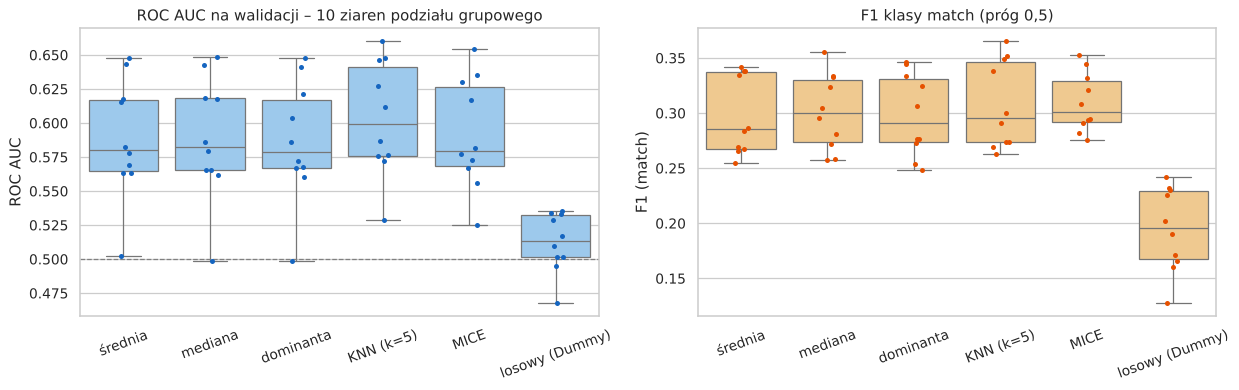

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=results, x="imputacja", y="ROC AUC", ax=axes[0], color="#90caf9")
sns.stripplot(data=results, x="imputacja", y="ROC AUC", ax=axes[0], color="#1565c0", size=4)
axes[0].axhline(0.5, color="grey", linestyle="--", linewidth=1)
axes[0].set_title("ROC AUC na walidacji – 10 ziaren podziału grupowego")
sns.boxplot(data=results, x="imputacja", y="F1 (match)", ax=axes[1], color="#ffcc80")
sns.stripplot(data=results, x="imputacja", y="F1 (match)", ax=axes[1], color="#e65100", size=4)
axes[1].set_title("F1 klasy match (próg 0,5)")
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
    axis.set_xlabel("")
fig.tight_layout()
fig.savefig(OUT / "boxplot_seeds.png", dpi=150, bbox_inches="tight")
plt.show()

### Wpływ ziarna samego modelu
Regresja logistyczna (solver lbfgs) jest deterministyczna, więc zmienność powyżej wynika tylko z podziału danych. Dla porównania model z losowością wewnętrzną – las losowy (200 drzew, bez strojenia) – na **jednym** stałym podziale i 10 różnych ziarnach modelu.

In [8]:
fit_index, val_index = validation_splits[0]
forest_rows = []
for seed in SEEDS:
    forest = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                    min_samples_leaf=5, n_jobs=-1, random_state=seed)
    pipeline = make_pipeline("mediana", forest)
    pipeline.fit(X_train_raw.iloc[fit_index], y_train.iloc[fit_index])
    probability = pipeline.predict_proba(X_train_raw.iloc[val_index])[:, 1]
    forest_rows.append({"seed": seed, **scores(y_train.iloc[val_index], probability)})
forest_results = pd.DataFrame(forest_rows)
forest_results[["ROC AUC", "AP", "balanced acc", "F1 (match)"]].agg(["mean", "std", "min", "max"]).round(3)

      ROC AUC     AP  balanced acc  F1 (match)
mean    0.574  0.218         0.498       0.015
std     0.015  0.012         0.003       0.008
min     0.552  0.200         0.492       0.000
max     0.598  0.235         0.502       0.019

## 6. Wynik w zależności od rozmiaru zbioru treningowego

Dla 5 podziałów grupowych (walidacja = 20% fal, stała dla danego ziarna) uczymy model na 10%, 20%, …, 100% części treningowej (losowanie wierszy ze stratyfikacją klasy). Pokazuje to, czy więcej danych pomogłoby modelowi.

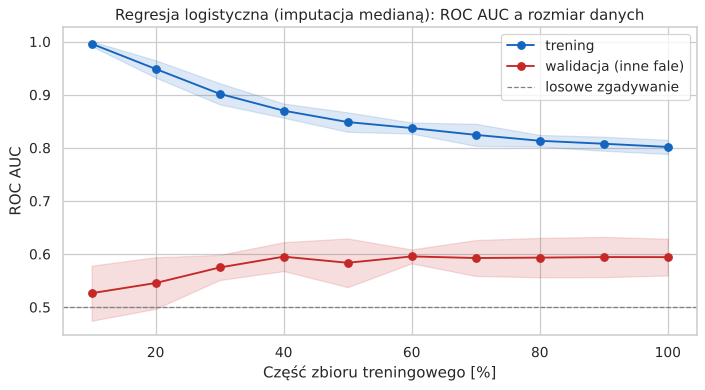

        n_train           train        walidacja       
           mean      std   mean    std      mean    std
frakcja                                                
0.1       260.2   30.817  0.996  0.005     0.526  0.052
0.2       520.2   61.779  0.949  0.016     0.545  0.049
0.3       780.0   92.661  0.902  0.020     0.575  0.024
0.4      1039.8  123.542  0.870  0.013     0.595  0.027
0.5      1300.2  154.440  0.849  0.018     0.584  0.046
0.6      1560.8  185.217  0.837  0.010     0.596  0.013
0.7      1820.6  216.098  0.825  0.021     0.593  0.034
0.8      2080.4  246.979  0.813  0.011     0.593  0.037
0.9      2340.4  277.945  0.808  0.013     0.594  0.038
1.0      2600.6  308.758  0.802  0.013     0.594  0.035

In [9]:
fractions = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
curve_rows = []
for seed, (fit_index, val_index) in zip(SEEDS[:5], validation_splits[:5]):
    rng = np.random.default_rng(seed)
    y_fit = y_train.iloc[fit_index]
    for fraction in fractions:
        chosen = []
        for label in (0, 1):  # stratyfikacja: ten sam udział matchy w każdej frakcji
            positions = np.flatnonzero(y_fit.values == label)
            chosen.extend(rng.choice(positions, size=max(2, int(round(fraction * len(positions)))), replace=False))
        subset = np.array(fit_index)[np.sort(chosen)]
        pipeline = make_pipeline("mediana", baseline_model(seed))
        pipeline.fit(X_train_raw.iloc[subset], y_train.iloc[subset])
        curve_rows.append({"seed": seed, "frakcja": fraction, "n_train": len(subset),
                           "train": roc_auc_score(y_train.iloc[subset],
                                                  pipeline.predict_proba(X_train_raw.iloc[subset])[:, 1]),
                           "walidacja": roc_auc_score(y_train.iloc[val_index],
                                                      pipeline.predict_proba(X_train_raw.iloc[val_index])[:, 1])})
curve = pd.DataFrame(curve_rows)
curve_summary = curve.groupby("frakcja")[["n_train", "train", "walidacja"]].agg(["mean", "std"]).round(3)

fig, ax = plt.subplots(figsize=(8, 4.5))
for column, color, label in [("train", "#1565c0", "trening"), ("walidacja", "#c62828", "walidacja (inne fale)")]:
    mean = curve.groupby("frakcja")[column].mean()
    std = curve.groupby("frakcja")[column].std()
    ax.plot(np.array(fractions) * 100, mean, "o-", color=color, label=label)
    ax.fill_between(np.array(fractions) * 100, mean - std, mean + std, color=color, alpha=0.15)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1, label="losowe zgadywanie")
ax.set_xlabel("Część zbioru treningowego [%]")
ax.set_ylabel("ROC AUC")
ax.set_title("Regresja logistyczna (imputacja medianą): ROC AUC a rozmiar danych")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()
curve_summary

## 7. Wykres wielu zmiennych na płaszczyźnie 2D

Cztery zmienne naraz: oś X – korelacja zainteresowań pary (`int_corr`), oś Y – różnica wieku (mężczyzna − kobieta), kolor heksagonu – **udział matchy** w danym obszarze, dwa panele – para tej samej rasy (`samerace`) lub nie. Tylko dane treningowe.

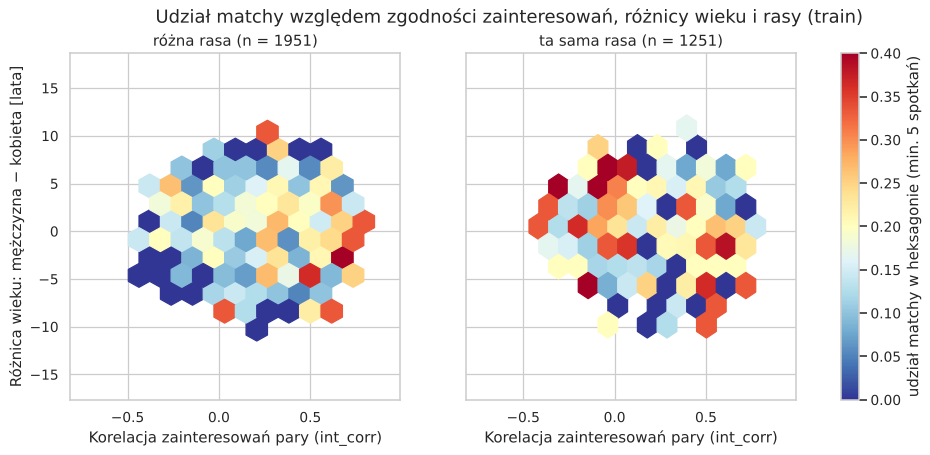

udział matchy: ta sama rasa 0.184 | różna rasa 0.155
korelacja int_corr z match: 0.034


In [10]:
plot_data = X_train_raw[["int_corr_woman", "age_diff", "samerace_woman"]].assign(match=y_train.values).dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for axis, same in zip(axes, [0, 1]):
    part = plot_data[plot_data["samerace_woman"] == same]
    hb = axis.hexbin(part["int_corr_woman"], part["age_diff"], C=part["match"], reduce_C_function=np.mean,
                     gridsize=14, cmap="RdYlBu_r", vmin=0, vmax=0.4, mincnt=5)
    axis.set_title(("ta sama rasa" if same else "różna rasa") + f" (n = {len(part)})")
    axis.set_xlabel("Korelacja zainteresowań pary (int_corr)")
axes[0].set_ylabel("Różnica wieku: mężczyzna − kobieta [lata]")
fig.colorbar(hb, ax=axes, label="udział matchy w heksagonie (min. 5 spotkań)")
fig.suptitle("Udział matchy względem zgodności zainteresowań, różnicy wieku i rasy (train)")
fig.savefig(OUT / "wykres_4_zmienne.png", dpi=150, bbox_inches="tight")
plt.show()
print("udział matchy: ta sama rasa", round(plot_data.loc[plot_data.samerace_woman == 1, "match"].mean(), 3),
      "| różna rasa", round(plot_data.loc[plot_data.samerace_woman == 0, "match"].mean(), 3))
print("korelacja int_corr z match:", round(plot_data["int_corr_woman"].corr(plot_data["match"]), 3))

## 8. Ocena końcowa na zbiorze testowym

Procedura zamrożona na podstawie walidacji: regresja logistyczna bez strojenia + imputacja **medianą** (wyniki imputacji są w granicach jednego odchylenia standardowego, więc wybieramy najprostszą). Dopasowanie na całym train, jednorazowa ocena na teście (fale niewidziane wcześniej).

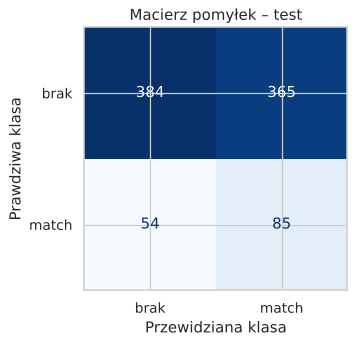

                      ROC AUC     AP  balanced acc  F1 (match)  accuracy
regresja logistyczna    0.571  0.202         0.562       0.289     0.528
losowy (Dummy)          0.482  0.153         0.482       0.132     0.718
zawsze „brak matcha”    0.500  0.157         0.500       0.000     0.843

In [11]:
final_pipeline = make_pipeline("mediana", baseline_model())
final_pipeline.fit(X_train_raw, y_train)
test_probability = final_pipeline.predict_proba(X_test_raw)[:, 1]
test_scores = scores(y_test, test_probability)

dummy_pipeline = make_pipeline("mediana", DummyClassifier(strategy="stratified", random_state=SEED))
dummy_pipeline.fit(X_train_raw, y_train)
dummy_scores = scores(y_test, dummy_pipeline.predict_proba(X_test_raw)[:, 1])
always_no = {"accuracy": accuracy_score(y_test, np.zeros_like(y_test)),
             "balanced acc": 0.5, "F1 (match)": 0.0, "ROC AUC": 0.5, "AP": y_test.mean()}

test_table = pd.DataFrame({"regresja logistyczna": test_scores, "losowy (Dummy)": dummy_scores,
                           "zawsze „brak matcha”": always_no}).T.round(3)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, (test_probability >= 0.5).astype(int)),
                       display_labels=["brak", "match"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Macierz pomyłek – test")
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
fig.tight_layout()
fig.savefig(OUT / "macierz_pomylek_test.png", dpi=150, bbox_inches="tight")
plt.show()
test_table

## 9. Zapis wyników do raportu
Liczby w raporcie (`raport/wyniki.tex`) pochodzą bezpośrednio z tego notatnika.

In [12]:
def tex_number(value, digits=3):
    return f"{value:.{digits}f}".replace(".", "{,}")


macros = {
    "NTrain": len(train), "NTest": len(test),
    "MatchTrain": tex_number(100 * y_train.mean(), 1), "MatchTest": tex_number(100 * y_test.mean(), 1),
    "NCech": X_train_raw.shape[1], "NDuplikaty": len(duplicated),
    "ValAucMean": tex_number(summary.loc["mediana", ("ROC AUC", "mean")]),
    "ValAucStd": tex_number(summary.loc["mediana", ("ROC AUC", "std")]),
    "TestAuc": tex_number(test_scores["ROC AUC"]), "TestAp": tex_number(test_scores["AP"]),
    "TestBacc": tex_number(test_scores["balanced acc"]), "TestFone": tex_number(test_scores["F1 (match)"]),
    "TestAcc": tex_number(test_scores["accuracy"]),
    "DummyAuc": tex_number(dummy_scores["ROC AUC"]), "DummyFone": tex_number(dummy_scores["F1 (match)"]),
    "AlwaysNoAcc": tex_number(always_no["accuracy"]),
    "ForestAucMean": tex_number(forest_results["ROC AUC"].mean()),
    "ForestAucStd": tex_number(forest_results["ROC AUC"].std()),
    "CurveFirst": tex_number(curve.groupby("frakcja")["walidacja"].mean().iloc[0]),
    "CurveLast": tex_number(curve.groupby("frakcja")["walidacja"].mean().iloc[-1]),
}
Path("raport").mkdir(exist_ok=True)
with open("raport/wyniki.tex", "w") as handle:
    handle.write("% Plik generowany automatycznie przez 4_etap1_model.ipynb – nie edytować ręcznie.\n")
    for key, value in macros.items():
        handle.write(f"\\newcommand{{\\{key}}}{{{value}}}\n")

# tabela do raportu: średnia ± odchylenie z 10 podziałów walidacyjnych
lines = [r"\begin{table}[H]", r"\centering",
         r"\caption{Walidacja (10 podziałów grupowych): średnia $\pm$ odchylenie standardowe.}",
         r"\label{tab:val}", r"\scriptsize", r"\setlength{\tabcolsep}{4pt}", r"\begin{tabular}{@{}lccc@{}}", r"\toprule",
         r"Imputacja & ROC AUC & AP & F1 (match)\\", r"\midrule"]
for name, row in summary.iterrows():
    cells = [f"{tex_number(row[(m, 'mean')])} $\\pm$ {tex_number(row[(m, 'std')])}" for m in ["ROC AUC", "AP", "F1 (match)"]]
    lines.append(f"{name} & " + " & ".join(cells) + r"\\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
Path("raport/tabela_walidacja.tex").write_text("\n".join(lines) + "\n")

summary_flat = summary.copy()
summary_flat.columns = [f"{a} {b}" for a, b in summary_flat.columns]
export = {"walidacja": summary_flat.reset_index().to_dict(orient="records"),
          "las_losowy_seedy": forest_results.round(4).to_dict(orient="records"),
          "krzywa": curve.groupby("frakcja")[["n_train", "train", "walidacja"]].mean().round(4).reset_index().to_dict(orient="records"),
          "imputacja": imputation_table.to_dict(orient="records"),
          "test": test_table.reset_index().to_dict(orient="records"),
          "usuniete_rzadkie": too_sparse, "duplikaty": duplicated}
(OUT / "wyniki_etap1.json").write_text(json.dumps(export, ensure_ascii=False, indent=1))
print(open("raport/wyniki.tex").read())

% Plik generowany automatycznie przez 4_etap1_model.ipynb – nie edytować ręcznie.
\newcommand{\NTrain}{3296}
\newcommand{\NTest}{888}
\newcommand{\MatchTrain}{16{,}7}
\newcommand{\MatchTest}{15{,}7}
\newcommand{\NCech}{123}
\newcommand{\NDuplikaty}{19}
\newcommand{\ValAucMean}{0{,}588}
\newcommand{\ValAucStd}{0{,}045}
\newcommand{\TestAuc}{0{,}571}
\newcommand{\TestAp}{0{,}202}
\newcommand{\TestBacc}{0{,}562}
\newcommand{\TestFone}{0{,}289}
\newcommand{\TestAcc}{0{,}528}
\newcommand{\DummyAuc}{0{,}482}
\newcommand{\DummyFone}{0{,}132}
\newcommand{\AlwaysNoAcc}{0{,}843}
\newcommand{\ForestAucMean}{0{,}574}
\newcommand{\ForestAucStd}{0{,}015}
\newcommand{\CurveFirst}{0{,}526}
\newcommand{\CurveLast}{0{,}594}

